In [1]:
# 01 · Data collection, cleaning & exploratory analysis
# AI-use disclosure: developed with the help of Claude Code (Anthropic). AI-assisted: code structure, the
# data-processing and model code (src/ and this notebook) and plotting code. Done by the student
# (B. G. M. Prabuddhi): choice of problem and data, data and modelling decisions, reviewing and running the
# code, interpreting the results. Details: AI_DISCLOSURE.md | Written analysis: reports/ANALYSIS.md

import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

In [2]:
from src import data
dengue = data.build_clean_datasets()
raw = pd.read_csv(config.DENGUE_RAW_CSV)
print("raw rows:", len(raw), "| clean rows:", len(dengue))
print("period:", dengue.start_date.min().date(), "->", dengue.end_date.max().date())
print("regions:", dengue.district.nunique())
dengue.head()

raw rows: 26753 | clean rows: 26753
period: 2006-12-23 -> 2026-09-13
regions: 26


,district,start_date,end_date,year,week,cases,missing_report,missing_reason
0,Ampara,2006-12-23,2006-12-29,2006,52,0.0,False,None
1,Ampara,2006-12-30,2007-01-05,2007,1,0.0,False,None
2,Ampara,2007-01-06,2007-01-12,2007,2,0.0,False,None
3,Ampara,2007-01-13,2007-01-19,2007,3,0.0,False,None
4,Ampara,2007-01-20,2007-01-26,2007,4,0.0,False,None


In [3]:
print("Raw spellings fixed:", data.NAME_FIXES)
print("Raw date formats: slash =", raw["start.date"].str.contains("/").sum(), "| ISO =", raw["start.date"].str.contains("-").sum())

# Example of the label problem: raw labels vs our rebuilt calendar around New Year
ex = raw[(raw.district == "Colombo") & raw["start.date"].isin(["12/16/2023", "12/23/2023", "12/13/2025", "12/20/2025", "12/29/2025"])]
fixed = dengue[(dengue.district == "Colombo") & dengue.start_date.isin(pd.to_datetime(ex["start.date"], format="mixed"))]
pd.concat([ex[["start.date", "year", "week"]].reset_index(drop=True).add_prefix("raw_"),
           fixed[["year", "week"]].reset_index(drop=True).add_prefix("clean_")], axis=1)

Raw spellings fixed: {'Hambanthota': 'Hambantota', 'NuwaraEliya': 'Nuwara Eliya', 'Kalmune': 'Kalmunai'}
Raw date formats: slash = 26311 | ISO = 442


,raw_start.date,raw_year,raw_week,clean_year,clean_week
0,12/16/2023,2023.0,51.0,2023,51
1,12/23/2023,2024.0,1.0,2023,52
2,12/13/2025,2025.0,52.0,2025,50
3,12/20/2025,2026.0,53.0,2025,51
4,12/29/2025,2026.0,1.0,2026,1


In [4]:
flagged = dengue[dengue.missing_report]
print("flagged district-weeks:", len(flagged), f"({100*len(flagged)/len(dengue):.2f}% of rows)")
print("by reason:", flagged.missing_reason.value_counts().to_dict())
print("whole weeks flagged (scrambled / duplicate):",
      sorted({str(d.date()) for d in flagged[flagged.missing_reason.isin(["scrambled", "duplicate"])].start_date}))

# Evidence for the national gap weeks: number of zero-reporting regions around them
zeros = raw.assign(sd=pd.to_datetime(raw["start.date"], format="mixed")).groupby("sd").cases.apply(lambda s: (s == 0).sum())
for gap in ["2012-06-16", "2022-09-10"]:
    g = pd.Timestamp(gap)
    print(f"\nregions reporting 0 around {gap}:", {str(k.date()): int(v) for k, v in zeros[g - pd.Timedelta(weeks=3): g + pd.Timedelta(weeks=3)].items()})

flagged district-weeks: 570 (2.13% of rows)
by reason: {'full_year': 366, 'duplicate': 104, 'scrambled': 52, 'dropout': 25, 'gap_week': 23}
whole weeks flagged (scrambled / duplicate): ['2012-01-21', '2021-12-18', '2025-02-08', '2026-03-30', '2026-06-08', '2026-06-22']

regions reporting 0 around 2012-06-16: {'2012-05-26': 19, '2012-06-02': 17, '2012-06-09': 18, '2012-06-16': 20, '2012-06-23': 14, '2012-06-30': 15, '2012-07-07': 13}

regions reporting 0 around 2022-09-10: {'2022-08-20': 2, '2022-08-27': 4, '2022-09-03': 6, '2022-09-10': 23, '2022-09-17': 2, '2022-09-24': 2, '2022-10-01': 1}


In [5]:
# Evidence for the 'scrambled' and 'duplicate' weeks in 2026: raw counts for selected regions
rawp = raw.assign(sd=pd.to_datetime(raw["start.date"], format="mixed"), district=raw.district.replace(data.NAME_FIXES)) \
          .pivot(index="district", columns="sd", values="cases")
cols = [pd.Timestamp(x) for x in ["2026-03-23", "2026-03-30", "2026-04-06", "2026-06-01", "2026-06-08", "2026-06-15", "2026-06-22", "2026-06-29"]]
ev = rawp.loc[["Colombo", "Gampaha", "Kalutara", "Matale", "Kilinochchi", "Mannar", "Galle"], cols].astype(int)
ev.columns = [c.strftime("%d %b") for c in cols]
ev   # 30 Mar & 8 Jun: big regions collapse while small ones explode; 22 Jun repeats 15 Jun exactly

,23 Mar,30 Mar,06 Apr,01 Jun,08 Jun,15 Jun,22 Jun,29 Jun
district,,,,,,,,
Colombo,316,9,291,507,20,1138,1138,1264
Gampaha,194,10,145,502,24,1294,1294,1439
Kalutara,122,10,165,318,53,551,551,866
Matale,17,256,18,38,889,49,49,81
Kilinochchi,4,117,1,4,419,6,6,2
Mannar,1,47,3,5,387,5,5,6
Galle,114,170,93,150,742,281,281,404


In [6]:
print("missing values:\n", dengue.isna().sum().to_dict())
print("duplicate district-weeks:", dengue.duplicated(["district", "start_date"]).sum())
gaps = dengue[dengue.district == "Colombo"].start_date.diff().dt.days.value_counts().sort_index()
print("gap between consecutive reporting weeks (days -> count):", gaps.to_dict())
dengue.cases.describe().round(1)

missing values:
 {'district': 0, 'start_date': 0, 'end_date': 0, 'year': 0, 'week': 0, 'cases': 570, 'missing_report': 0, 'missing_reason': 26183}
duplicate district-weeks: 0


gap between consecutive reporting weeks (days -> count): {6.0: 1, 7.0: 1025, 8.0: 1, 9.0: 1}


count    26183.0
mean        33.8
std         86.4
min          0.0
25%          2.0
50%         10.0
75%         31.0
max       2631.0
Name: cases, dtype: float64

In [7]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s > q3 + 3 * (q3 - q1)

ok = dengue[dengue.cases.notna()].copy()
ok["extreme"] = ok.groupby("district").cases.transform(iqr_outliers)
print(f"extreme district-weeks (> Q3 + 3*IQR within district): {ok.extreme.sum()} ({ok.extreme.mean():.1%})")
by_year = ok.groupby("year").extreme.sum()
print("extreme weeks by year:", by_year[by_year > 0].to_dict())
top_years = by_year.sort_values(ascending=False).head(4)
print(f"share in the 4 biggest years {sorted(top_years.index.tolist())}: {top_years.sum() / by_year.sum():.0%}")
same_week = ok[ok.extreme].groupby("start_date").district.transform("nunique")   # extreme regions in that week
for k in (3, 5, 10):
    print(f"extreme district-weeks occurring while >= {k:2d} regions are extreme at the same time: {(same_week >= k).mean():.0%}")
print("-> most extreme weeks are shared by many regions at once (epidemics), so they are real and are kept")

extreme district-weeks (> Q3 + 3*IQR within district): 1000 (3.8%)
extreme weeks by year: {2009: 22, 2010: 26, 2011: 3, 2012: 2, 2014: 9, 2016: 5, 2017: 384, 2018: 44, 2019: 165, 2020: 48, 2021: 15, 2022: 10, 2023: 72, 2024: 39, 2025: 6, 2026: 150}
share in the 4 biggest years [2017, 2019, 2023, 2026]: 77%
extreme district-weeks occurring while >=  3 regions are extreme at the same time: 79%
extreme district-weeks occurring while >=  5 regions are extreme at the same time: 67%
extreme district-weeks occurring while >= 10 regions are extreme at the same time: 51%
-> most extreme weeks are shared by many regions at once (epidemics), so they are real and are kept


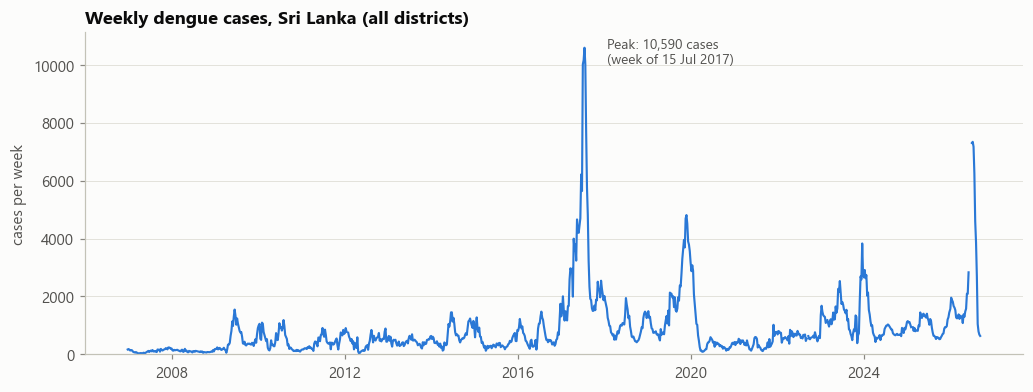

Annual totals:
 year
2006       167
2007      6019
2008      5715
2009     26552
2010     25006
2011     21647
2012     22748
2013     23021
2014     35650
2015     22180
2016     34355
2017    174687
2018     51321
2019     97949
2020     29404
2021     19091
2022     31674
2023     73678
2024     52873
2025     48293
2026     83015


In [8]:
nat = data.national_weekly(dengue)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(nat.index, nat.values, color=viz.SERIES[0], lw=1.4)
peak = nat.idxmax()
ax.annotate(f"Peak: {int(nat.max()):,} cases\n(week of {peak:%d %b %Y})", xy=(peak, nat.max()),
            xytext=(15, -10), textcoords="offset points", color=viz.INK_2, fontsize=9)
ax.set_title("Weekly dengue cases, Sri Lanka (all districts)")
ax.set_ylabel("cases per week"); ax.set_ylim(0)
viz.save(fig, "eda_national_trend"); plt.show()

annual = dengue.groupby("year").cases.sum().astype(int)   # 2006 = 1 week only; 2026 = up to 13 Sep
print("Annual totals:\n", annual.to_string())

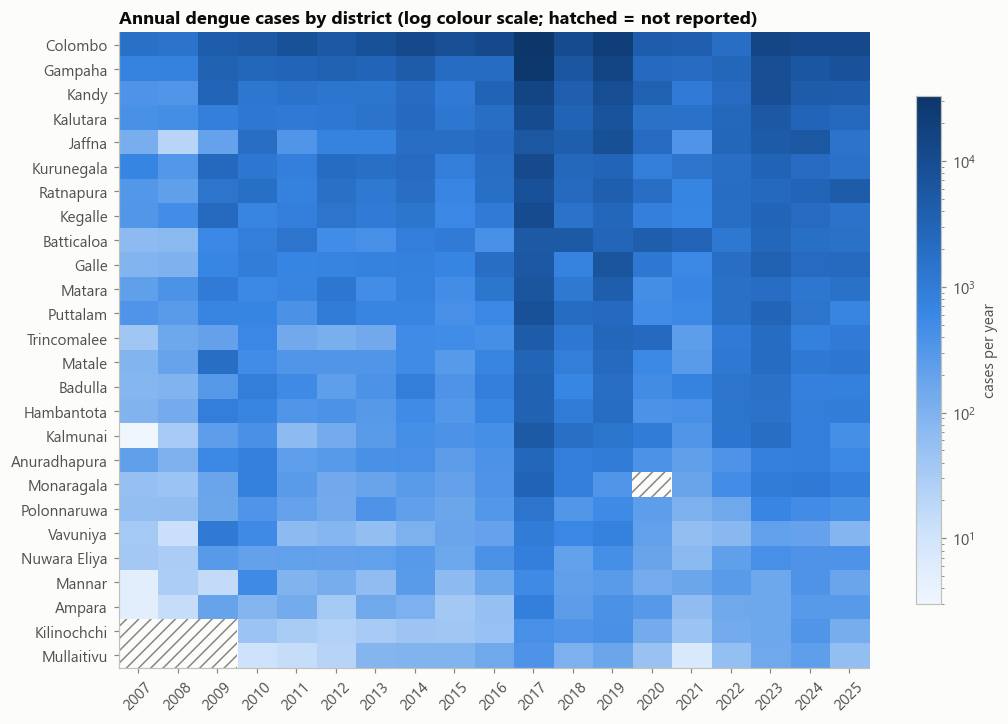

Share of all 2007-2025 cases (%):
 district
Colombo       21.8
Gampaha       12.8
Kandy          8.3
Kalutara       6.1
Jaffna         5.6
Kurunegala     5.2
Ratnapura      4.9
Kegalle        4.2
Batticaloa     4.1
Galle          3.9


In [9]:
from matplotlib.colors import LogNorm
full_years = dengue[dengue.year.between(2007, 2025)]          # complete calendar years only
# min_count=1 keeps a year that was never reported as NaN instead of a misleading 0
heat = full_years.groupby(["district", "year"]).cases.sum(min_count=1).unstack()
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 7.5))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", viz.SEQ_BLUE)
im = ax.imshow(np.ma.masked_invalid(heat.values), aspect="auto", cmap=cmap,
               norm=LogNorm(vmin=max(np.nanmin(heat.values), 1), vmax=np.nanmax(heat.values)))
# Hatch the not-reported cells so they cannot be mistaken for "low"
for (i, j) in zip(*np.where(heat.isna().values)):
    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor=viz.SURFACE, edgecolor=viz.MUTED, hatch="///", lw=0))
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=45); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False); ax.set_title("Annual dengue cases by district (log colour scale; hatched = not reported)")
fig.colorbar(im, ax=ax, label="cases per year", shrink=0.8)
viz.save(fig, "eda_district_heatmap"); plt.show()

share = (heat.sum(axis=1) / np.nansum(heat.values) * 100).round(1)
print("Share of all 2007-2025 cases (%):\n", share.head(10).to_string())

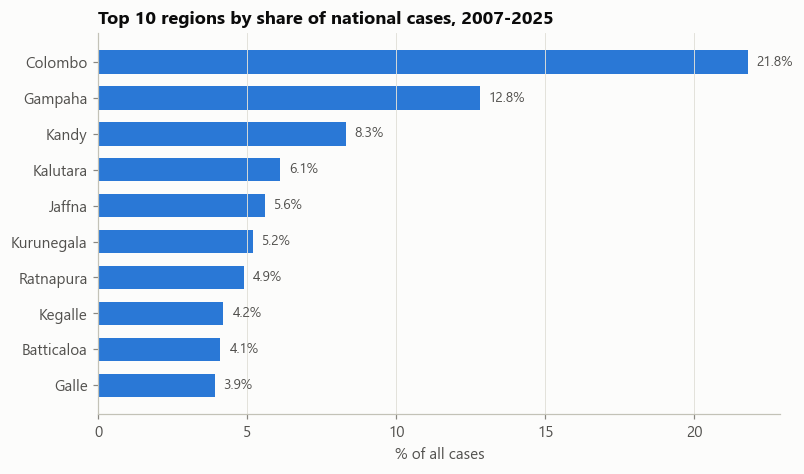

In [10]:
top10 = share.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index, top10.values, color=viz.SERIES[0], height=0.65)
for i, v in enumerate(top10.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", color=viz.INK_2, fontsize=9)
ax.set_title("Top 10 regions by share of national cases, 2007-2025")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.set_xlabel("% of all cases")
viz.save(fig, "eda_top10_districts"); plt.show()

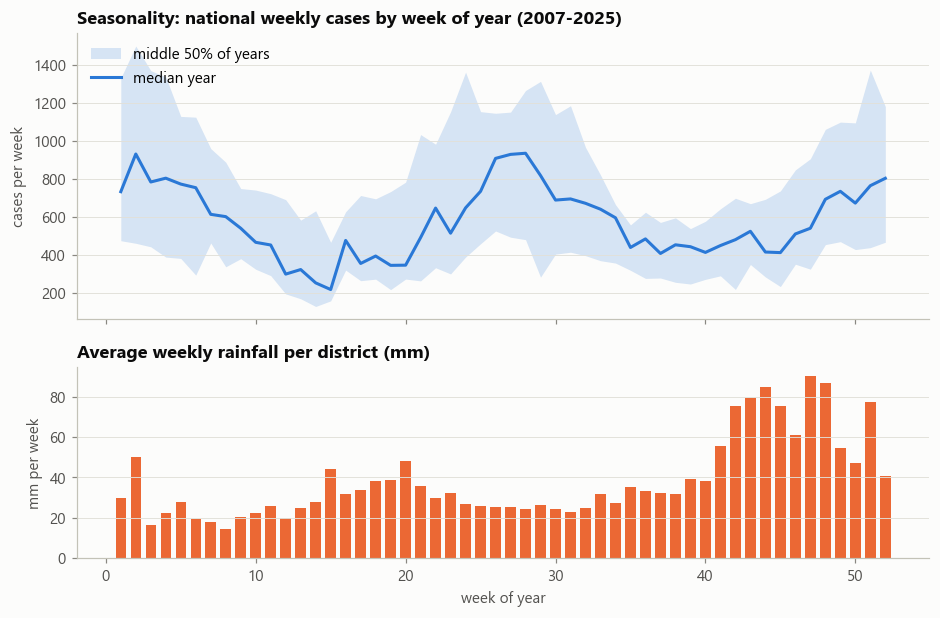

Peak median week: 28 | trough median week: 15


In [11]:
# Week 53 exists only in a few years, so it is left out of the typical-year profile.
cal = dengue.drop_duplicates("start_date").set_index("start_date")[["year", "week"]]
nat_df = cal.assign(cases=nat).dropna()
nat_df = nat_df[nat_df.year.between(2007, 2025) & (nat_df.week <= 52)]
q = nat_df.groupby("week").cases.quantile([.25, .5, .75]).unstack()

wx = data.load_weather_weekly()
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax = axes[0]
ax.fill_between(q.index, q[.25], q[.75], color=viz.SERIES[0], alpha=0.18, lw=0, label="middle 50% of years")
ax.plot(q.index, q[.5], color=viz.SERIES[0], label="median year")
ax.set_title("Seasonality: national weekly cases by week of year (2007-2025)"); ax.set_ylabel("cases per week"); ax.legend(loc="upper left")
if wx is not None:
    wxm = wx.merge(dengue[["district", "start_date", "year", "week"]], on=["district", "start_date"])
    rain = wxm[wxm.year.between(2007, 2025) & (wxm.week <= 52)].groupby("week").rain_mm.mean()
    axes[1].bar(rain.index, rain.values, color=viz.SERIES[1], width=0.7)
    axes[1].set_title("Average weekly rainfall per district (mm)"); axes[1].set_ylabel("mm per week")
axes[1].set_xlabel("week of year")
viz.save(fig, "eda_seasonality"); plt.show()
print("Peak median week:", int(q[.5].idxmax()), "| trough median week:", int(q[.5].idxmin()))

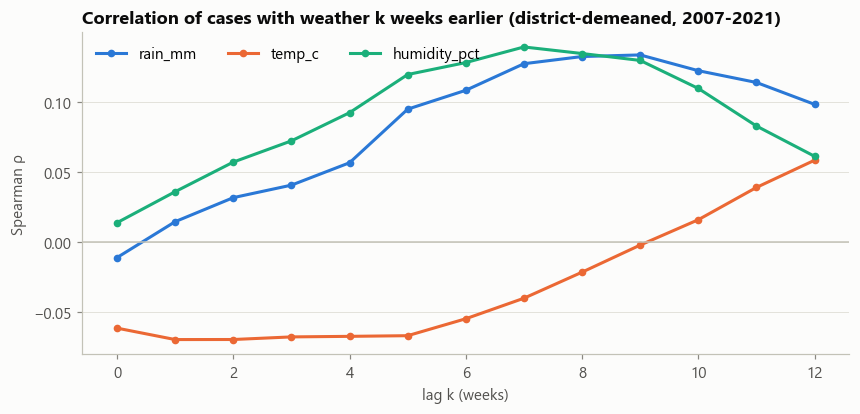

var  humidity_pct  rain_mm  temp_c
lag                               
0           0.014   -0.011  -0.062
1           0.036    0.014  -0.070
2           0.057    0.031  -0.070
3           0.072    0.040  -0.068
4           0.092    0.056  -0.068
5           0.119    0.095  -0.067
6           0.128    0.108  -0.055
7           0.139    0.127  -0.040
8           0.134    0.132  -0.022
9           0.129    0.133  -0.002
10          0.109    0.122   0.016
11          0.083    0.114   0.039
12          0.061    0.098   0.058
Weekly-aggregation coverage (days per week -> count): {7: 26701, 8: 26, 6: 26}


In [12]:
if wx is None:
    print("Weather unavailable - skipping.")
else:
    m = dengue.merge(wx, on=["district", "start_date"]).sort_values(["district", "start_date"])
    m = m[m.year <= config.TRAIN_END_YEAR]                         # look at training years only
    m["log_cases"] = np.log1p(m.cases)
    m["log_cases_dm"] = m.log_cases - m.groupby("district").log_cases.transform("mean")
    rows = []
    for var in config.WEATHER_VARS:
        dm = m[var] - m.groupby("district")[var].transform("mean")
        for k in range(0, 13):
            lagged = dm.groupby(m.district).shift(k)
            rows.append({"var": var, "lag": k, "rho": m.log_cases_dm.corr(lagged, method="spearman")})
    cc = pd.DataFrame(rows).pivot(index="lag", columns="var", values="rho")
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for i, var in enumerate(config.WEATHER_VARS):
        ax.plot(cc.index, cc[var], marker="o", ms=4, color=viz.SERIES[i], label=var)
    ax.axhline(0, color=viz.AXIS, lw=1)
    ax.set_title("Correlation of cases with weather k weeks earlier (district-demeaned, 2007-2021)")
    ax.set_xlabel("lag k (weeks)"); ax.set_ylabel("Spearman ρ"); ax.legend(ncol=3, loc="upper left")
    viz.save(fig, "eda_weather_lag_correlation"); plt.show()
    print(cc.round(3).to_string())
    print("Weekly-aggregation coverage (days per week -> count):", wx.n_days.value_counts().to_dict())

In [13]:
ac = {k: dengue.groupby("district").cases.apply(lambda s: s.autocorr(k)).median() for k in [1, 2, 4, 8, 26, 52]}
print("Median (across districts) autocorrelation of weekly cases at lag k:")
print({k: round(v, 3) for k, v in ac.items()})
print("Share of zero-case district-weeks: %.1f%%" % (100 * (dengue.cases == 0).mean()))

Median (across districts) autocorrelation of weekly cases at lag k:
{1: 0.893, 2: 0.818, 4: 0.664, 8: 0.381, 26: 0.124, 52: 0.075}
Share of zero-case district-weeks: 12.1%


In [14]:
split = np.select([dengue.year <= config.TRAIN_END_YEAR, dengue.year == config.VAL_YEAR], ["train", "validation"], "test")
summary = dengue.assign(split=split).groupby("split").agg(rows=("cases", "size"), start=("start_date", "min"),
                                                          end=("end_date", "max"), mean_cases=("cases", "mean"))
summary.loc[["train", "validation", "test"]]

,rows,start,end,mean_cases
split,,,,
train,20384,2006-12-23,2021-12-31,29.851722
validation,1352,2022-01-01,2022-12-30,23.850904
test,5017,2022-12-31,2026-09-13,52.559927
